# Partie 1 : Donnees Mouse

Les dix dernieres observations du fichier sont considerees comme anomalies de reference uniquement pour levaluation. Le vecteur y_reference est construit avant toute operation de melange ou de partitionnement et nest jamais fourni aux methodes non supervises.


In [1]:
from pathlib import Path
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from utils import fit_isolation_forest, fit_lof, load_mouse_data, plot_scores

SEED = 42
N_REFERENCE_OUTLIERS = 10
DATA_PATH = Path("mouse.txt")
np.random.seed(SEED)

print(f"Python : {platform.python_version()}")
print(f"NumPy : {np.__version__}")
print(f"pandas : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")


Python : 3.13.5
NumPy : 2.3.4
pandas : 2.3.3
scikit-learn : 1.7.2


## 1.a Chargement, verification et visualisation

Le fichier ne contient pas de cible. On crie donc y_reference a partir de sa position dans le fichier : 0 pour les observations normales et 1 pour les dix dernieres observations.


Dimensions de X : (500, 2)
Valeurs manquantes : 0
Nombre dobservations normales : 490
Nombre danomalies de reference : 10


,x1,x2
0,0.456601,0.432806
1,0.611378,0.528625
2,0.450299,0.711606
3,0.639015,0.460744
4,0.628957,0.323470


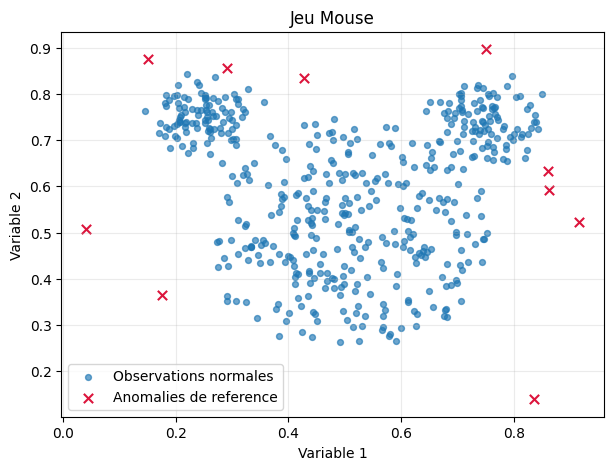

In [2]:
X, y_reference = load_mouse_data(DATA_PATH, n_reference_outliers=N_REFERENCE_OUTLIERS)

print(f"Dimensions de X : {X.shape}")
print(f"Valeurs manquantes : {np.isnan(X).sum()}")
print(f"Nombre dobservations normales : {(y_reference == 0).sum()}")
print(f"Nombre danomalies de reference : {(y_reference == 1).sum()}")
display(pd.DataFrame(X, columns=["x1", "x2"]).head())

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X[y_reference == 0, 0], X[y_reference == 0, 1], s=18, alpha=0.65, label="Observations normales")
ax.scatter(X[y_reference == 1, 0], X[y_reference == 1, 1], s=45, marker="x", color="crimson", label="Anomalies de reference")
ax.set(title="Jeu Mouse", xlabel="Variable 1", ylabel="Variable 2")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


## 1.b : Isolation Forest et LOF

La contamination est fixee  10 / 500, conformement au nombre d anomalies de reference. Les scores sont orientes de sorte qu une valeur elevee signifie une observation plus anormale.


In [3]:
contamination = N_REFERENCE_OUTLIERS / len(X)

t0 = time.perf_counter()
isolation_forest, if_labels, if_scores = fit_isolation_forest(X, contamination=contamination, random_state=SEED)
if_fit_time = time.perf_counter() - t0

t0 = time.perf_counter()
lof_train, lof_train_labels, lof_train_scores, lof_novelty, lof_novelty_scores = fit_lof(X, n_neighbors=20, contamination=contamination)
lof_fit_time = time.perf_counter() - t0

print(f"Isolation Forest : apprentissage + scores : {if_fit_time:.4f} s")
print(f"LOF : apprentissage + scores : {lof_fit_time:.4f} s")
print(f"Outliers detectes par Isolation Forest : {(if_labels == -1).sum()}")
print(f"Outliers detectes par LOF : {(lof_train_labels == -1).sum()}")


Isolation Forest : apprentissage + scores : 0.3337 s
LOF : apprentissage + scores : 0.0096 s
Outliers detectes par Isolation Forest : 10
Outliers detectes par LOF : 10


### Isolation Forest : points detectes, score et histogramme


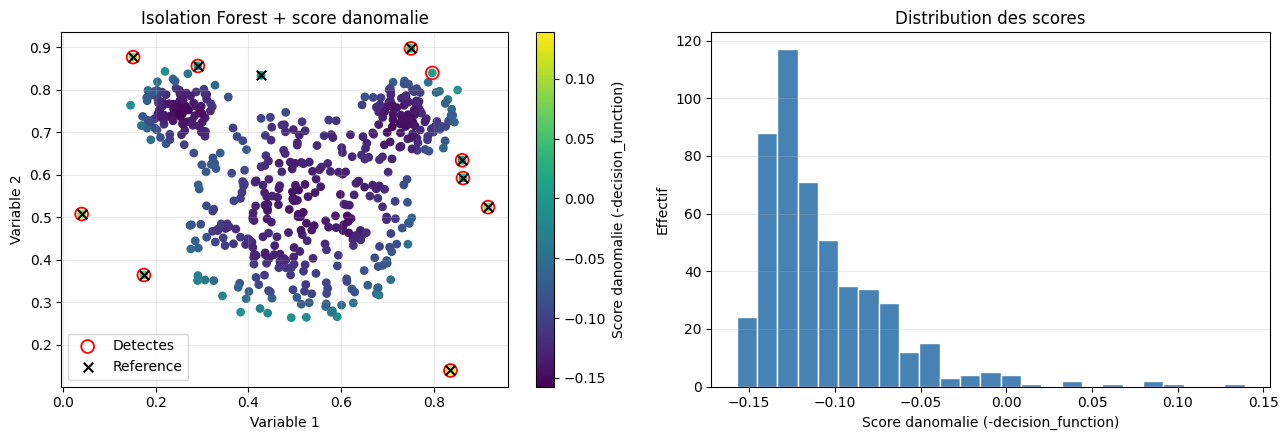

In [4]:
plot_scores(
    X, if_scores, if_labels,
    title="Isolation Forest + score danomalie",
    score_label="Score danomalie (-decision_function)",
    reference_labels=y_reference,
)


### LOF : score dapprentissage et score de nouveaute

Avec novelty=False (usage transductif), LOF expose negative_outlier_factor_ sur les observations utilisees pour lapprentissage. Avec novelty=True, il faut ajuster un second modele et utiliser score_samples pour scorer de nouvelles observations. Ces deux scores ne sont pas definis exactement de la mme facon ; ils sont affiches separement.


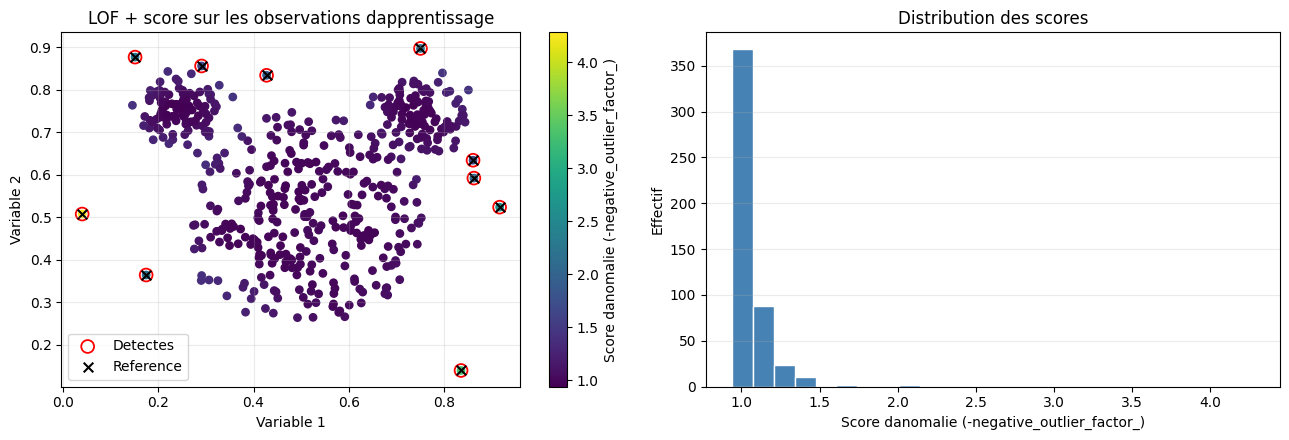

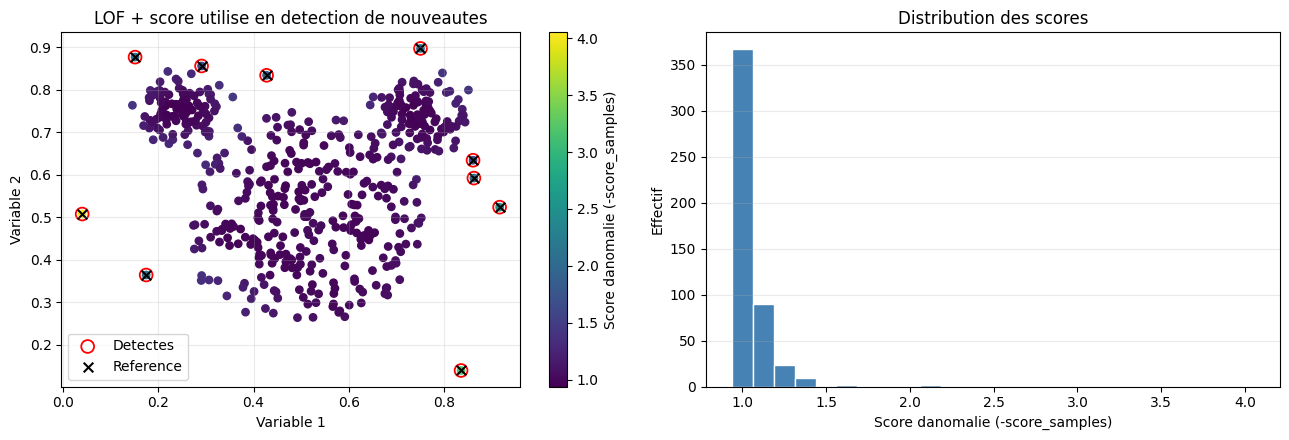

In [5]:
plot_scores(
    X, lof_train_scores, lof_train_labels,
    title="LOF + score sur les observations dapprentissage",
    score_label="Score danomalie (-negative_outlier_factor_)",
    reference_labels=y_reference,
)

novelty_labels = np.where(
    lof_novelty_scores >= np.quantile(lof_novelty_scores, 1 - contamination), -1, 1
)
plot_scores(
    X, lof_novelty_scores, novelty_labels,
    title="LOF + score utilise en detection de nouveautes",
    score_label="Score danomalie (-score_samples)",
    reference_labels=y_reference,
)


In [6]:
summary = pd.DataFrame({
    "methode": ["Isolation Forest", "LOF (apprentissage)", "LOF (nouveaute)"],
    "temps_apprentissage_s": [if_fit_time, lof_fit_time, lof_fit_time],
    "nombre_outliers": [int((if_labels == -1).sum()), int((lof_train_labels == -1).sum()), int((novelty_labels == -1).sum())],
})
display(summary)
print("Les etiquettes de reference ont uniquement servi a distinguer visuellement les dix derniers points.")


,methode,temps_apprentissage_s,nombre_outliers
0,Isolation Forest,0.333663,10
1,LOF (apprentissage),0.009614,10
2,LOF (nouveaute),0.009614,10


Les etiquettes de reference ont uniquement servi a distinguer visuellement les dix derniers points.


## 2 .Choisir un seuil sans tiquettes

Les seuils heuristiques ci-dessous sont calcules uniquement a partir des scores. Les etiquettes y_reference sont utilisees apres cette etape, uniquement pour mesurer la qualite des decisions.


In [7]:
from utils import (
    evaluate_predictions,
    iqr_upper_threshold,
    labels_from_score_threshold,
    ranking_metrics,
)


### 2.a  Seuil fonde sur lecart interquartile

Pour chaque mthode, on calcule Q1, Q3 et IQR = Q3 - Q1. Une observation est declaree anomalie lorsque son score verifie :

score >= Q3 + 1.5  IQR

Le facteur 1.5 est fix avant levaluation et ne depend pas des etiquettes de reference.


In [8]:
methods = {
    "Isolation Forest": (if_scores, if_labels),
    "LOF (apprentissage)": (lof_train_scores, lof_train_labels),
}

results = []
for method_name, (scores, default_labels) in methods.items():
    threshold = iqr_upper_threshold(scores, multiplier=1.5)
    iqr_labels = labels_from_score_threshold(scores, threshold)
    iqr_evaluation = evaluate_predictions(y_reference, iqr_labels)
    default_evaluation = evaluate_predictions(y_reference, default_labels)

    print(f"\n{method_name}")
    print(f"Seuil IQR : {threshold:.6f}")
    print("Points dtects avec le seuil IQR :", iqr_evaluation["detected_indices"].tolist())
    print("Matrice de confusion IQR (lignes = rel, colonnes = prdit) :\n", iqr_evaluation["confusion_matrix"])
    f1_iqr = iqr_evaluation["f1_anomalie"]
    print(f"F1 anomalie IQR : {f1_iqr:.4f}")
    print("Points dtects avec le seuil par dfaut :", default_evaluation["detected_indices"].tolist())
    print("Matrice de confusion par dfaut (lignes = rel, colonnes = prdit) :\n", default_evaluation["confusion_matrix"])
    f1_default = default_evaluation["f1_anomalie"]
    print(f"F1 anomalie par dfaut : {f1_default:.4f}")

    results.extend([
        {
            "mthode": method_name,
            "seuil": "IQR",
            "valeur_seuil": threshold,
            "nombre_dtects": len(iqr_evaluation["detected_indices"]),
            "F1_anomalie": iqr_evaluation["f1_anomalie"],
        },
        {
            "mthode": method_name,
            "seuil": "Dfaut",
            "valeur_seuil": np.nan,
            "nombre_dtects": len(default_evaluation["detected_indices"]),
            "F1_anomalie": default_evaluation["f1_anomalie"],
        },
    ])

display(pd.DataFrame(results))



Isolation Forest
Seuil IQR : -0.027165
Points dtects avec le seuil IQR : [84, 111, 194, 197, 217, 220, 265, 291, 387, 398, 424, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499]
Matrice de confusion IQR (lignes = rel, colonnes = prdit) :
 [[479  11]
 [  0  10]]
F1 anomalie IQR : 0.6452
Points dtects avec le seuil par dfaut : [424, 490, 491, 492, 493, 494, 495, 496, 497, 498]
Matrice de confusion par dfaut (lignes = rel, colonnes = prdit) :
 [[489   1]
 [  1   9]]
F1 anomalie par dfaut : 0.9000

LOF (apprentissage)
Seuil IQR : 1.225625
Points dtects avec le seuil IQR : [14, 32, 72, 84, 165, 189, 220, 223, 265, 291, 294, 296, 308, 323, 342, 347, 359, 367, 387, 388, 398, 420, 424, 425, 466, 470, 479, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499]
Matrice de confusion IQR (lignes = rel, colonnes = prdit) :
 [[463  27]
 [  0  10]]
F1 anomalie IQR : 0.4255
Points dtects avec le seuil par dfaut : [490, 491, 492, 493, 494, 495, 496, 497, 498, 499]
Matrice de confusion par dfaut (lignes = r

,mthode,seuil,valeur_seuil,nombre_dtects,F1_anomalie
0,Isolation Forest,IQR,-0.027165,21,0.645161
1,Isolation Forest,Dfaut,NaN,10,0.900000
2,LOF (apprentissage),IQR,1.225625,37,0.425532
3,LOF (apprentissage),Dfaut,NaN,10,1.000000


### 2.c  AP et AUC-ROC

LAP (Average Precision) et lAUC-ROC valuent le classement produit par les scores sur une gamme de seuils. Elles ne dpendent donc pas dun seul seuil de dcision.


In [9]:
ranking_results = []
for method_name, (scores, _) in methods.items():
    metrics = ranking_metrics(y_reference, scores)
    ranking_results.append({
        "mthode": method_name,
        "AP": metrics["average_precision"],
        "AUC-ROC": metrics["roc_auc"],
    })

display(pd.DataFrame(ranking_results))


,mthode,AP,AUC-ROC
0,Isolation Forest,0.961429,0.99898
1,LOF (apprentissage),1.000000,1.00000


**Interprtation :** modifier uniquement le seuil transforme les scores continus en labels (normal ou anomalie). Cela peut modifier la matrice de confusion et le F1, mais pas les scores eux-mmes. Or lAP et lAUC-ROC utilisent le classement des scores pour considrer plusieurs seuils ; elles restent donc inchanges lorsquon modifie seulement le seuil. Ces mesures dcrivent ici la dtection sur lchantillon Mouse observ, et ne constituent pas une estimation des performances sur de futures donnes.
